# De la señal a la pseudodistancia: qué mide un receptor GNSS

Este cuaderno acompaña la unidad de *sistemas de posicionamiento satelital (GNSS)*. Parte de un día de datos reales —la estación permanente **BOGT** (Bogotá, red IGS, operada por NASA/JPL), 15 de septiembre de 2026— y llega, término a término, hasta la **ecuación de la pseudodistancia**, el punto de partida de todo el posicionamiento por satélite.

Cada sección sigue el mismo patrón: una definición breve, el cálculo con los datos, y una figura. Los datos están en `data/` (regla del curso: ningún cuaderno depende de descargas externas).

**El archivo `bogt_20260915_gps.csv`** tiene una fila por época y satélite GPS, preparada a partir de los archivos RINEX de la estación:

| columna | qué es | unidad |
|---|---|---|
| `t` | instante de la medida (época), en tiempo GPS | fecha y hora |
| `sv` | satélite (G + número PRN) | — |
| `P1`, `P2` | pseudodistancia medida con el código en las portadoras L1 y L2 | m |
| `L1` | fase de la portadora L1 (conteo de ciclos) | ciclos |
| `S1` | intensidad de la señal recibida en L1 | dB·Hz |
| `xs`, `ys`, `zs` | posición del satélite en el instante en que emitió la señal, calculada con sus efemérides | m (geocéntricas) |
| `dts` | corrección del reloj del satélite, calculada con los coeficientes que él mismo transmite | s |
| `el`, `az` | elevación y acimut del satélite vistos desde BOGT | grados |

> **Estación GNSS permanente** — receptor con antena fija que registra sin interrupción las señales de los satélites de navegación y publica sus datos. BOGT pertenece al **IGS** (*International GNSS Service*), la red mundial de estaciones de este tipo que existe desde 1994.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
AZUL, ROJO, VERDE, GRIS, NARANJA = "#1F3864", "#9C0006", "#375623", "#7F7F7F", "#C55A11"

# velocidad de la luz en el vacío (m/s): valor exacto, porque define el metro en el SI
C = 299_792_458.0

# el dato común: una fila por época y satélite GPS
D = pd.read_csv("data/bogt_20260915_gps.csv", parse_dates=["t"])

# la posición publicada de la estación (X, Y, Z geocéntricas, en metros)
lineas = open("data/bogt_20260915_estacion.txt").read().splitlines()[1:]
est = dict(linea.split() for linea in lineas)
rx = np.array([float(est["X"]), float(est["Y"]), float(est["Z"])])

print("filas:", len(D), "| épocas:", D.t.nunique(), "| satélites distintos:", D.sv.nunique())
print("BOGT (X, Y, Z) =", rx)
D.head()

filas: 27312 | épocas: 2880 | satélites distintos: 32
BOGT (X, Y, Z) = [ 1744399.0397 -6116037.5577   512731.7532]


,t,sv,P1,P2,L1,S1,xs,ys,zs,dts,el,az
0,2026-09-15,G01,2.286695e+07,2.286696e+07,1.201667e+08,43.00,7.296331e+06,-1.744863e+07,-1.861866e+07,0.000172,28.206,173.659
1,2026-09-15,G02,2.136431e+07,2.136431e+07,1.122703e+08,46.00,1.350578e+07,-1.873477e+07,-1.218097e+07,0.000176,41.830,150.537
2,2026-09-15,G03,2.381813e+07,2.381813e+07,1.251650e+08,41.25,-4.519559e+06,-1.798759e+07,-1.925986e+07,0.000267,19.728,204.363
3,2026-09-15,G04,2.035627e+07,2.035627e+07,1.069731e+08,48.50,2.989410e+05,-2.631631e+07,2.755613e+06,0.000065,70.010,275.736
4,2026-09-15,G08,2.000519e+07,2.000520e+07,1.051282e+08,50.50,5.720878e+06,-2.429087e+07,8.143931e+06,0.000346,72.002,349.231


## 1. La estación y sus coordenadas geocéntricas

> **Coordenadas geocéntricas (X, Y, Z)** — sistema cartesiano con origen en el centro de masa de la Tierra, eje Z hacia el polo norte, eje X hacia el meridiano de Greenwich y eje Y completando la terna a 90°. Es el sistema en el que se publican las posiciones de los satélites y el que usa el receptor para calcular.

La posición de BOGT se conoce con precisión (se publica en el encabezado de sus archivos). Convertirla a latitud, longitud y altura sobre el elipsoide es un cálculo geodésico estándar; aquí se hace con el elipsoide WGS84 y un método iterativo.

In [2]:
def xyz_a_geodesicas(X, Y, Z, a=6378137.0, f=1/298.257223563):
    """Coordenadas geocéntricas (m) -> latitud y longitud (grados) y altura elipsoidal (m).
    a, f: semieje mayor y aplanamiento del elipsoide (WGS84). Iteración clásica sobre la latitud."""
    e2 = f * (2 - f)                       # excentricidad al cuadrado
    lon = np.arctan2(Y, X)                 # la longitud sale directa
    p = np.hypot(X, Y)                     # distancia al eje de rotación
    lat = np.arctan2(Z, p * (1 - e2))      # primera aproximación de la latitud
    for _ in range(10):                    # se refina la latitud (converge en pocas vueltas)
        N = a / np.sqrt(1 - e2 * np.sin(lat) ** 2)     # radio de curvatura en el primer vertical
        h = p / np.cos(lat) - N                         # altura sobre el elipsoide
        lat = np.arctan2(Z, p * (1 - e2 * N / (N + h)))
    return np.degrees(lat), np.degrees(lon), h

lat, lon, h = xyz_a_geodesicas(*rx)
print(f"BOGT: latitud {lat:.5f}°, longitud {lon:.5f}°, altura elipsoidal {h:.1f} m")
print(f"distancia al centro de la Tierra: {np.linalg.norm(rx)/1e3:.1f} km")

BOGT: latitud 4.64007°, longitud -74.08094°, altura elipsoidal 2576.8 m
distancia al centro de la Tierra: 6380.6 km


## 2. Una época: los satélites visibles y un número para cada uno

> **Época** — instante en el que el receptor registra, a la vez, una medida de cada satélite que tiene a la vista. BOGT registra una época cada 30 s: 2 880 al día.

A las 12:00:00 (tiempo GPS) hay medición de nueve satélites GPS. El valor de `P1` para cada uno está entre 20 y 24 millones de metros: es una **distancia**. La estación no mide ángulos ni «ve» los satélites; mide **qué tan lejos está cada uno**.

In [3]:
t0 = pd.Timestamp("2026-09-15 12:00:00")          # la época de trabajo (tiempo GPS)
ep = D[D.t == t0].sort_values("P1").reset_index(drop=True)   # las filas de esa época, de menor a mayor distancia

tabla = ep[["sv", "P1", "P2", "el", "az"]].copy()
tabla["P1_km"] = tabla.P1 / 1e3
tabla.round({"P1": 3, "P2": 3, "el": 1, "az": 1, "P1_km": 0})

,sv,P1,P2,el,az,P1_km
0,G15,2.022137e+07,2.022137e+07,68.5,315.8,20221.0
1,G29,2.149618e+07,2.149618e+07,47.3,308.5,21496.0
2,G20,2.149660e+07,2.149660e+07,46.9,21.7,21497.0
3,G24,2.206766e+07,2.206766e+07,40.6,165.1,22068.0
4,G11,2.281779e+07,2.281779e+07,29.8,93.2,22818.0
5,G05,2.342492e+07,2.342492e+07,22.1,17.3,23425.0
6,G13,2.365321e+07,2.365321e+07,19.6,191.4,23653.0
7,G12,2.386724e+07,2.386724e+07,22.3,196.5,23867.0
8,G25,2.412188e+07,2.412188e+07,17.5,230.0,24122.0


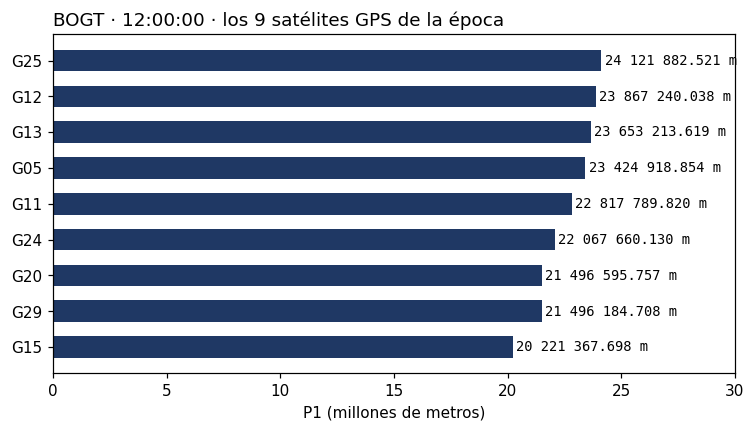

In [4]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(ep.sv, ep.P1 / 1e6, color=AZUL, height=0.6)
for sv, valor in zip(ep.sv, ep.P1):
    ax.text(valor / 1e6 + 0.15, sv, f"{valor:,.3f} m".replace(",", " "), va="center", family="monospace", fontsize=9)
ax.set_xlim(0, 30)
ax.set_xlabel("P1 (millones de metros)")
ax.set_title("BOGT · 12:00:00 · los 9 satélites GPS de la época", loc="left");

## 3. Un satélite a lo largo del día

Siguiendo un solo satélite (G15) durante horas, la distancia baja, pasa por un mínimo y vuelve a subir: el satélite **sale por el horizonte, culmina y se oculta**. En el mínimo está cerca de la vertical de la estación, así que ese mínimo es aproximadamente la **altura de la órbita** (unos 20 200 km). La columna `el` (elevación sobre el horizonte, en grados) confirma la lectura.

G15 visible de 08:55 a 15:09 (374 min)
distancia mínima 20,180,322 m a las 11:45:30, con elevación 72.5°


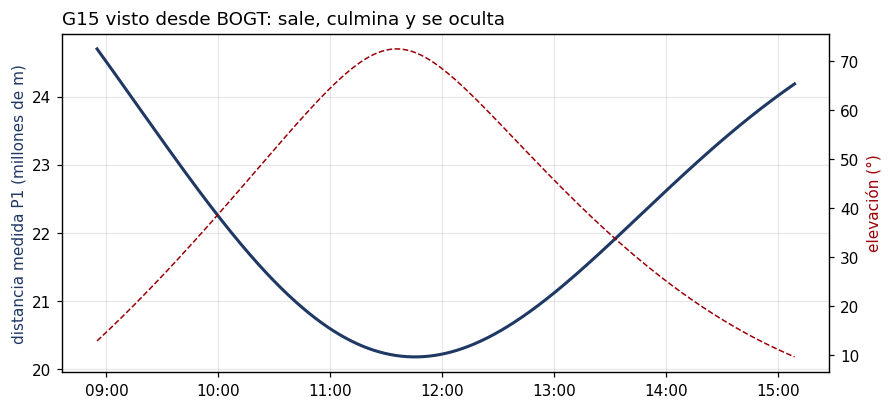

In [5]:
g15 = D[D.sv == "G15"].set_index("t").sort_index()

# un "pase" es el tramo continuo en que el satélite estuvo visible: se corta donde hay un hueco de más de 5 min
hueco = g15.index.to_series().diff() > pd.Timedelta("5min")
numero_de_pase = hueco.cumsum()
pase_de_las_12 = numero_de_pase[g15.index[g15.index.get_indexer([t0], method="nearest")[0]]]
pase = g15[numero_de_pase == pase_de_las_12]

duracion_min = (pase.index[-1] - pase.index[0]).total_seconds() / 60
print(f"G15 visible de {pase.index[0].strftime('%H:%M')} a {pase.index[-1].strftime('%H:%M')} ({duracion_min:.0f} min)")
print(f"distancia mínima {pase.P1.min():,.0f} m a las {pase.P1.idxmin().strftime('%H:%M:%S')}, con elevación {pase.el.max():.1f}°")

fig, ax1 = plt.subplots(figsize=(9, 4))
ax2 = ax1.twinx()                                   # segundo eje para la elevación
ax1.plot(pase.index, pase.P1 / 1e6, color=AZUL, lw=2)
ax2.plot(pase.index, pase.el, color=ROJO, lw=1, ls="--")
ax1.set_ylabel("distancia medida P1 (millones de m)", color=AZUL)
ax2.set_ylabel("elevación (°)", color=ROJO)
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
ax1.set_title("G15 visto desde BOGT: sale, culmina y se oculta", loc="left")
ax1.grid(alpha=0.3);

## 4. Cuántos satélites se ven a la vez

Los satélites entran y salen continuamente, pero nunca faltan. La línea de **cuatro** marca el mínimo con el que un receptor puede calcular su posición (tres coordenadas y su propio reloj, como se verá al final).

satélites GPS por época: mínimo 7, máximo 12, media 9.5


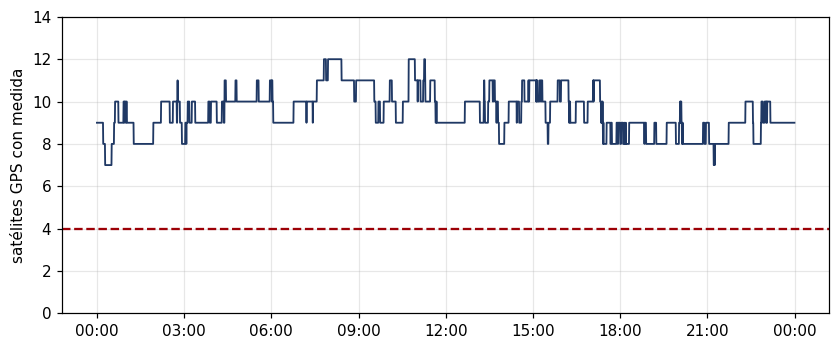

In [6]:
n_por_epoca = D.groupby("t").sv.count()             # cuántos satélites tienen medida en cada época
print(f"satélites GPS por época: mínimo {n_por_epoca.min()}, máximo {n_por_epoca.max()}, media {n_por_epoca.mean():.1f}")

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(n_por_epoca.index, n_por_epoca.values, color=AZUL, lw=1.2)
ax.axhline(4, color=ROJO, ls="--")
ax.set_ylim(0, 14)
ax.set_ylabel("satélites GPS con medida")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
ax.grid(alpha=0.3);

## 5. La distancia se mide con un reloj

> El receptor no mide metros: mide **cuánto tarda la señal en llegar**. Si la señal sale del satélite en el instante $t^s$ y llega en $t_R$, la distancia recorrida es $d = c\,(t_R - t^s)$, con $c = 299\,792\,458$ m/s.

Esa igualdad convierte errores de tiempo en errores de distancia: 1 ns son 30 cm; 1 µs, 300 m; 1 ms, 300 km. Medir 20 000 km con precisión de metros exige medir tiempos con precisión de **nanosegundos**: por eso los satélites llevan relojes atómicos.

In [7]:
for dt, nombre in [(1e-9, "1 ns"), (1e-6, "1 µs"), (1e-3, "1 ms")]:
    print(f"{nombre:>6} de error en el tiempo -> {C*dt:>12,.2f} m de error en la distancia".replace(",", " "))

P15 = float(ep.loc[ep.sv == "G15", "P1"].iloc[0])   # la pseudodistancia de G15 a las 12:00
tau = P15 / C                                        # tiempo de viaje de la señal (s)
print(f"\nG15 a las 12:00:00: P1 = {P15:,.3f} m  ->  tiempo de viaje = {tau*1e3:.3f} ms".replace(",", " "))

  1 ns de error en el tiempo ->         0.30 m de error en la distancia
  1 µs de error en el tiempo ->       299.79 m de error en la distancia
  1 ms de error en el tiempo ->   299 792.46 m de error en la distancia

G15 a las 12:00:00: P1 = 20 221 367.698 m  ->  tiempo de viaje = 67.451 ms


## 6. Dónde estaba el satélite: la posición que viene en el mensaje

Cada satélite transmite sus **efemérides** (los seis elementos de su órbita más pequeñas correcciones) y con ellas se calcula dónde estaba en el instante de emisión. Esa posición ya está en el archivo (`xs, ys, zs`). Su distancia al centro de la Tierra, unos 26 500 km, es el radio de la órbita: restando el radio terrestre (6 371 km) queda la altura de unos 20 200 km.

Con geometría elemental: un satélite en la vertical del receptor está a $a - R$ km; uno en el horizonte, a $\sqrt{a^2 - R^2}$ km. Es exactamente el rango de la curva de la sección 3.

In [8]:
ep["radio_km"] = np.sqrt(ep["xs"]**2 + ep["ys"]**2 + ep["zs"]**2) / 1e3   # distancia del satélite al centro de la Tierra
print(ep[["sv", "radio_km"]].round(1).to_string(index=False))

R_t = 6371.0      # radio medio de la Tierra (km, IUGG)
a = 26560.0       # semieje mayor de la órbita GPS (km)
print(f"\nen el cenit: a - R = {a-R_t:,.0f} km   |   en el horizonte: sqrt(a² - R²) = {np.sqrt(a**2-R_t**2):,.0f} km".replace(",", " "))

 sv  radio_km
G15   26394.8
G29   26467.8
G20   26598.9
G24   26724.4
G11   26513.3
G05   26418.7
G13   26612.9
G12   26767.7
G25   26853.6

en el cenit: a - R = 20 189 km   |   en el horizonte: sqrt(a² - R²) = 25 785 km


## 7. Distancia medida y distancia geométrica: los relojes de los satélites

> **Distancia geométrica** $r$ — la distancia real entre el satélite (en el instante de emisión) y el receptor: $r = \sqrt{(x - x^s)^2 + (y - y^s)^2 + (z - z^s)^2}$.

Como la posición de BOGT se conoce, se puede calcular $r$ y compararla con la medida. **No coinciden**: difieren en ±100 km, un valor distinto para cada satélite. Son los **relojes de los satélites**: cada uno marca la hora de emisión con un adelanto o atraso propio de cientos de microsegundos (a 300 km por milisegundo). El satélite conoce su desviación —el segmento de control la mide y la sube al mensaje— y la transmite: es la columna `dts`.

In [9]:
# distancia geométrica: del satélite (en el instante de emisión) a la posición publicada de BOGT
ep["r"] = np.sqrt((rx[0] - ep["xs"])**2 + (rx[1] - ep["ys"])**2 + (rx[2] - ep["zs"])**2)

ep["P_menos_r"] = ep.P1 - ep.r          # medida − geométrica: debería ser ~0 si los relojes fueran perfectos
ep["c_dts"] = C * ep.dts                # error del reloj del satélite, pasado a metros
ep["resid"] = ep.P1 - ep.r + ep.c_dts   # lo que queda tras corregir el reloj del satélite

ep[["sv", "el", "P1", "r", "P_menos_r", "c_dts", "resid"]].round(3)

,sv,el,P1,r,P_menos_r,c_dts,resid
0,G15,68.513,2.022137e+07,2.035474e+07,-133369.109,133372.634,3.525
1,G29,47.305,2.149618e+07,2.142342e+07,72767.193,-72763.214,3.979
2,G20,46.896,2.149660e+07,2.158236e+07,-85759.609,85762.858,3.248
3,G24,40.558,2.206766e+07,2.213019e+07,-62533.631,62539.257,5.626
4,G11,29.830,2.281779e+07,2.275506e+07,62725.881,-62718.618,7.263
5,G05,22.068,2.342492e+07,2.335393e+07,70992.733,-70984.934,7.799
6,G13,19.560,2.365321e+07,2.378586e+07,-132642.357,132652.265,9.908
7,G12,22.278,2.386724e+07,2.368675e+07,180494.861,-180485.335,9.525
8,G25,17.461,2.412188e+07,2.423832e+07,-116435.256,116446.638,11.382


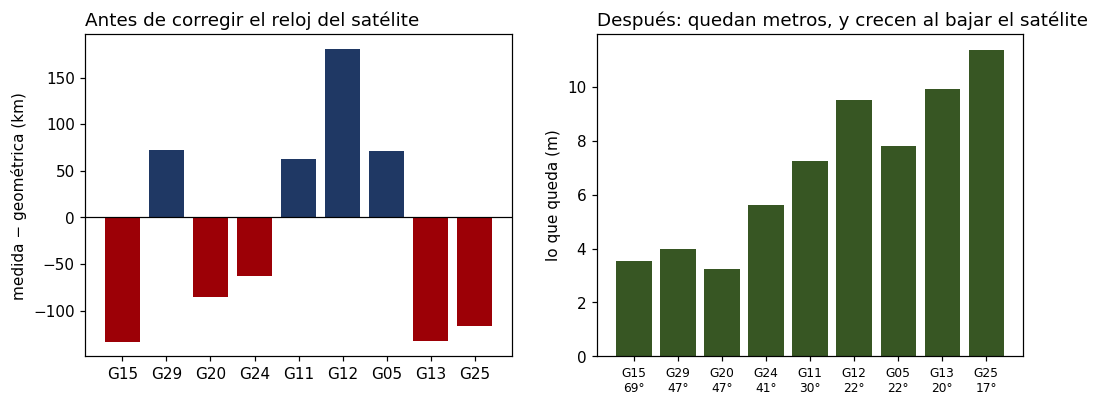

In [10]:
e2 = ep.sort_values("el", ascending=False)    # de más alto a más bajo sobre el horizonte
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))

colores = [ROJO if v < 0 else AZUL for v in e2.P_menos_r]
axs[0].bar(e2.sv, e2.P_menos_r / 1e3, color=colores)
axs[0].axhline(0, color="k", lw=0.8)
axs[0].set_ylabel("medida − geométrica (km)")
axs[0].set_title("Antes de corregir el reloj del satélite", loc="left")

axs[1].bar(e2.sv, e2.resid, color=VERDE)
axs[1].set_ylabel("lo que queda (m)")
axs[1].set_title("Después: quedan metros, y crecen al bajar el satélite", loc="left")
axs[1].set_xticks(range(len(e2)))
axs[1].set_xticklabels([f"{s}\n{e:.0f}°" for s, e in zip(e2.sv, e2.el)], fontsize=8);

## 8. Lo que queda depende de la elevación: la atmósfera

Tras corregir el reloj del satélite quedan unos metros, y son mayores para los satélites bajos. Siguiendo a G15 durante todo su pase se ve la forma: la señal de un satélite bajo atraviesa más atmósfera y llega más tarde. Además queda una parte común a todos los satélites de la época: el error del **reloj del receptor**, que se calculará como incógnita.

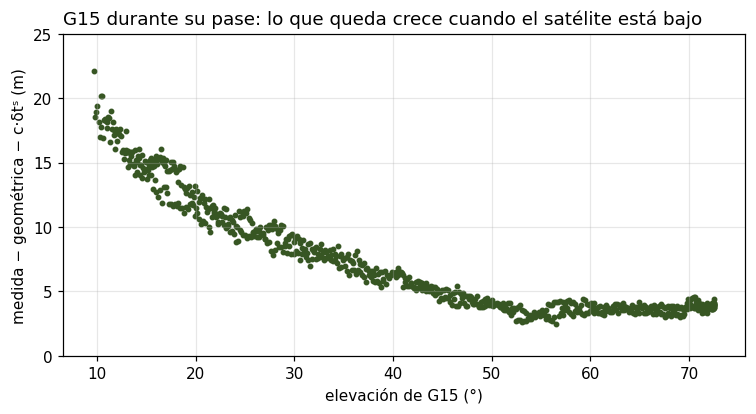

In [11]:
pase = pase.copy()
pase["r"] = np.sqrt((rx[0] - pase["xs"])**2 + (rx[1] - pase["ys"])**2 + (rx[2] - pase["zs"])**2)
pase["resid"] = pase.P1 - pase.r + C * pase.dts      # medida − geométrica − (−c·δtˢ)

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.scatter(pase.el, pase.resid, s=8, color=VERDE)
ax.set_xlabel("elevación de G15 (°)")
ax.set_ylabel("medida − geométrica − c·δtˢ (m)")
ax.set_ylim(0, 25)
ax.grid(alpha=0.3)
ax.set_title("G15 durante su pase: lo que queda crece cuando el satélite está bajo", loc="left");

## 9. La misma distancia en dos frecuencias: la huella de la ionosfera

El mismo satélite se mide a la vez en L1 (`P1`) y L2 (`P2`). Si el retraso de la señal no dependiera de la frecuencia, las dos distancias serían iguales. No lo son: la diferencia crece cuando el satélite está bajo y cuando el sol ya ha ionizado la atmósfera (el pase de G15 va de las 03:55 a las 10:09 hora de Colombia). Es la firma de la **ionosfera**, que retrasa más a la frecuencia más baja (L2). El desfase casi constante de la madrugada (unos −1,5 m) es instrumental: los circuitos de L1 y L2 no retrasan igual la señal.

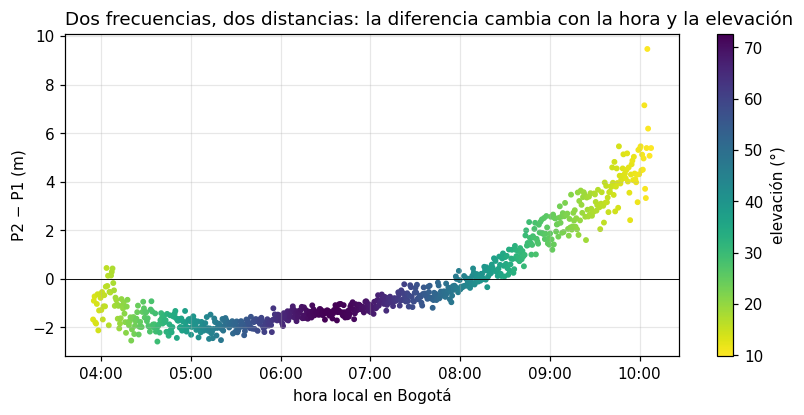

In [12]:
# tiempo GPS -> UTC (restar los 18 s intercalares) -> hora de Colombia (UTC−5)
hora_local = pase.index - pd.Timedelta(hours=5) - pd.Timedelta(seconds=18)

fig, ax = plt.subplots(figsize=(9, 3.8))
sc = ax.scatter(hora_local, pase.P2 - pase.P1, s=8, c=pase.el, cmap="viridis_r")
fig.colorbar(sc, ax=ax, label="elevación (°)")
ax.axhline(0, color="k", lw=0.6)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
ax.set_xlabel("hora local en Bogotá")
ax.set_ylabel("P2 − P1 (m)")
ax.set_title("Dos frecuencias, dos distancias: la diferencia cambia con la hora y la elevación", loc="left")
ax.grid(alpha=0.3);

## 10. La ecuación de la pseudodistancia

> **Pseudodistancia (*pseudorange*), $\rho$** — la distancia que mide el código: la geométrica más el efecto de los dos relojes y de todo lo demás.
> $$\rho = r + c\,(\delta t_R - \delta t^s) + \varepsilon$$
> $r$: distancia geométrica · $c$: velocidad de la luz · $\delta t_R$: error del reloj del receptor (desconocido) · $\delta t^s$: error del reloj del satélite (transmitido) · $\varepsilon$: atmósfera, reflexiones, ruido.

Con los números de G15 a las 12:00:00, todo cuadra: el reloj del satélite explica 133 km de diferencia y lo que queda son unos metros.

In [13]:
g = ep[ep.sv == "G15"].iloc[0]
print(f"ρ        = {g.P1:,.3f} m".replace(",", " "))
print(f"r        = {g.r:,.3f} m".replace(",", " "))
print(f"c·δtˢ    = {C*g.dts:,.1f} m   (δtˢ = {g.dts*1e6:.3f} µs)".replace(",", " "))
print(f"ρ − r + c·δtˢ = {g.P1 - g.r + C*g.dts:,.2f} m  = c·δt_R + ε".replace(",", " "))

ρ        = 20 221 367.698 m
r        = 20 354 736.807 m
c·δtˢ    = 133 372.6 m   (δtˢ = 444.883 µs)
ρ − r + c·δtˢ = 3.53 m  = c·δt_R + ε


## 11. Por qué hacen falta cuatro satélites

Para cada satélite $i$ de una época:
$$\rho_i + c\,\delta t^i = \sqrt{(x - x^i)^2 + (y - y^i)^2 + (z - z^i)^2} + c\,\delta t_R + \varepsilon_i$$
Lo conocido: $\rho_i$ (medido), $x^i, y^i, z^i, \delta t^i$ (del mensaje). Lo desconocido, y común a todas las ecuaciones: $x, y, z$ y $\delta t_R$. **Cuatro incógnitas** → hacen falta al menos cuatro satélites. BOGT tuvo nueve a las 12:00 y nunca menos de siete en el día. Resolver ese sistema es el tema del cuaderno `gnss_estimacion_posicion.ipynb`.

## Referencias

- IS-GPS-200, *Navstar GPS Space Segment/Navigation User Segment Interfaces* (gps.gov/technical/icwg): señal, mensaje de navegación, cálculo de la posición y el reloj del satélite.
- ESA Navipedia (gssc.esa.int/navipedia): GPS Space Segment, GPS Signal Plan, GPS Navigation Message.
- Leick, A., Rapoport, L. y Tatarnikov, D. (2015). *GPS Satellite Surveying*, 4.ª ed. Wiley.
- Blewitt, G. (1997). *Basics of the GPS Technique: Observation Equations, Software Developments, and Data Processing*.
- IGS, International GNSS Service (igs.org); datos de BOGT del centro de datos IGS en BKG (igs.bkg.bund.de). RINEX 3.04 (IGS/RTCM, 2018).